# Pregunta 3 — Monitoreo de fauna con cámaras trampa (YOLO sobre Caltech Camera Traps)

Notebook completo: lectura de los JSON de LILA, construcción de particiones *cis/trans*, exportación a formato YOLO, entrenamiento, evaluación, robustez, Grad-CAM y reporte ecológico.

**Archivos esperados (en la carpeta del notebook):**
- `caltech_bboxes_20200316.json` — cajas por animal (formato COCO: `bbox = [x, y, w, h]` en píxeles).
- `CaltechCameraTrapsSplits_v0.json` — particiones por ubicación (train / val / test).
- `caltech_images_20210113.json` — metadatos de todas las imágenes (ubicación, secuencia, fecha, etiqueta a nivel de imagen). **Supuse que este es el tercer archivo**, porque en tu mensaje `caltech_bboxes_20200316` aparece dos veces. Si no lo tienes, el notebook funciona igual, solo que sin imágenes vacías adicionales.
- `cct_images/` — todas las imágenes `.jpg` descomprimidas.

**Cómo se usa cada JSON:** el de *bboxes* da las cajas y las clases; el de *splits* decide qué ubicaciones van a entrenamiento y cuáles son ubicaciones nuevas; el de *images* aporta fecha, secuencia y las imágenes vacías.

La celda 3 imprime la estructura real de cada archivo. Si algún nombre de campo difiere de lo que asumo, se ajusta en la celda 4 (`COLS`).

In [ ]:
# 0. Dependencias (descomenta en Colab / entorno nuevo)
# !pip install -q ultralytics pandas matplotlib opencv-python pyyaml

In [1]:
# 1. Configuración
import json, os, random, shutil, warnings
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

ROOT        = Path(".")
BBOX_JSON   = ROOT / "caltech_bboxes_20200316.json"
SPLITS_JSON = ROOT / "CaltechCameraTrapsSplits_v0.json"
IMAGES_JSON = ROOT / "caltech_images_20210113.json"      # opcional
IMG_DIR     = ROOT / "cct_images"   # se busca de forma recursiva; si tus .jpg están junto al notebook, pon ROOT
WORK        = ROOT / "work_q3"
DATA        = WORK / "yolo_data"
RES         = WORK / "results"

SEED            = 42
EMPTY_RATIO     = 1.0    # vacías en train por cada imagen con animal (-1 = todas, 0 = ninguna)
EVAL_EMPTY_RATIO= -1     # en validación/prueba (-1 = todas las disponibles)
CIS_FRAC        = 0.10   # fracción de secuencias de ubicaciones de train reservadas para cis_val y para cis_test (c/u)
OVERSAMPLE_MAX  = 1      # >1 activa sobremuestreo de especies raras (factor máximo)
SPLIT_KEYS      = ("eccv_train", "eccv_val")   # CCT-20 (10 + 10 ubicaciones). Dataset completo: ("train", "val")
TRANS_VAL_FRAC  = 0.5    # de las ubicaciones nuevas (eccv_val), fracción que va a val_trans; el resto a test_trans

# Hiperparámetros YOLO
WEIGHTS = ROOT / "yolov8s.pt"   # pesos preentrenados, descargados a mano (ver celda de entrenamiento)
IMGSZ, EPOCHS, BATCH, PATIENCE = 640, 50, 16, 15
AUG = "strong"           # "base" o "strong"
EXP_NAME = f"yolov8s_{AUG}"
REEXPORT       = False   # True = borrar y volver a generar yolo_data (necesario si cambias splits, semilla, EMPTY_RATIO u OVERSAMPLE_MAX)
TRAIN_FRACTION = 1.0     # fracción del conjunto de train usada al entrenar (1.0 = todo)
try:
    import torch
    DEVICE = 0 if torch.cuda.is_available() else "cpu"
except ImportError:
    DEVICE = "cpu"
if DEVICE == "cpu":
    # Sin GPU CUDA: configuración ligera para que el entrenamiento sea viable. Para la corrida final usa GPU (Colab/Kaggle o torch con CUDA).
    print("AVISO: PyTorch no ve ninguna GPU CUDA -> entrenando en CPU con configuración ligera (yolov8n, 416 px, 15 épocas, 25 % de train).")
    WEIGHTS, IMGSZ, EPOCHS, BATCH, TRAIN_FRACTION = ROOT / "yolov8n.pt", 416, 15, 8, 0.25
    EXP_NAME = f"yolov8n_{AUG}_cpu"

random.seed(SEED); np.random.seed(SEED)
WORK.mkdir(exist_ok=True, parents=True); RES.mkdir(exist_ok=True, parents=True)

AVISO: PyTorch no ve ninguna GPU CUDA -> entrenando en CPU con configuración ligera (yolov8n, 416 px, 15 épocas, 25 % de train).


## 2. Lectura de los JSON

In [2]:
# 2. Carga cruda
bb = json.load(open(BBOX_JSON, encoding="utf-8"))
sp = json.load(open(SPLITS_JSON, encoding="utf-8"))
im_js = json.load(open(IMAGES_JSON, encoding="utf-8")) if IMAGES_JSON.exists() else None
print("bboxes  :", list(bb.keys()))
print("splits  :", list(sp.keys()))
print("images  :", list(im_js.keys()) if im_js else "(no encontrado)")

bboxes  : ['info', 'categories', 'annotations', 'images']
splits  : ['info', 'splits']
images  : ['images', 'annotations', 'categories', 'info']


In [3]:
# 3. Inspección de estructura (revisa que coincida con lo asumido)
print("--- bboxes: imagen de ejemplo");      print(bb["images"][0])
print("--- bboxes: anotación de ejemplo");   print(bb["annotations"][0])
print("--- bboxes: categorías");             print({c["id"]: c["name"] for c in bb["categories"]})
s = sp.get("splits", sp)
print("--- splits:", {k: (len(v), list(v)[:3]) for k, v in s.items() if isinstance(v, (list, dict))})
if im_js:
    print("--- images: imagen de ejemplo");    print(im_js["images"][0])
    print("--- images: anotación de ejemplo"); print(im_js["annotations"][0])

--- bboxes: imagen de ejemplo
{'file_name': '5998cfa4-23d2-11e8-a6a3-ec086b02610b.jpg', 'seq_id': '6f084ccc-5567-11e8-bc84-dca9047ef277', 'height': 1494, 'id': '5998cfa4-23d2-11e8-a6a3-ec086b02610b', 'frame_num': 1, 'width': 2048, 'date_captured': '2011-05-13 23:43:18', 'rights_holder': 'Justin Brown', 'seq_num_frames': 3, 'location': '33'}
--- bboxes: anotación de ejemplo
{'image_id': '5998cfa4-23d2-11e8-a6a3-ec086b02610b', 'id': '2a545520-cbf1-11e8-819c-970a9450cdbc', 'bbox': [499.2, 711.68, 353.28000000000003, 199.67999999999995], 'category_id': 1}
--- bboxes: categorías
{6: 'bobcat', 1: 'opossum', 30: 'empty', 9: 'coyote', 3: 'raccoon', 11: 'bird', 8: 'dog', 16: 'cat', 5: 'squirrel', 10: 'rabbit', 7: 'skunk', 14: 'lizard', 99: 'rodent', 21: 'badger', 34: 'deer', 37: 'cow', 33: 'car', 51: 'fox', 39: 'pig', 40: 'mountain_lion', 66: 'bat', 97: 'insect'}
--- splits: {'train': (120, ['10', '102', '103']), 'val': (40, ['0', '1', '100']), 'eccv_train': (30, ['33', '33', '33']), 'eccv_val'

## 3. Tabla de imágenes y anotaciones
Se normalizan los nombres de columnas (`COLS`), se toma solo el nombre base del archivo (por si `file_name` trae subcarpetas) y se descartan las imágenes que no existen en `cct_images/`.

In [4]:
# 4. DataFrames normalizados
COLS = dict(file=["file_name"], location=["location"], seq=["seq_id"], frame=["frame_num"],
            dt=["date_captured", "datetime"], w=["width"], h=["height"])
def pick(df, names, default=None):
    for n in names:
        if n in df.columns: return df[n]
    return pd.Series([default] * len(df), index=df.index)

def norm_images(images):
    df = pd.DataFrame(images)
    out = pd.DataFrame({"id": df["id"].astype(str)})
    out["file"]     = pick(df, COLS["file"]).astype(str).map(lambda s: os.path.basename(s))
    out["location"] = pick(df, COLS["location"]).astype(str)
    out["seq_id"]   = pick(df, COLS["seq"]).astype(str)
    out["frame"]    = pd.to_numeric(pick(df, COLS["frame"]), errors="coerce")
    out["dt"]       = pd.to_datetime(pick(df, COLS["dt"]), errors="coerce")
    out["W"]        = pd.to_numeric(pick(df, COLS["w"]), errors="coerce")
    out["H"]        = pd.to_numeric(pick(df, COLS["h"]), errors="coerce")
    return out

cats = {c["id"]: c["name"] for c in bb["categories"]}
EMPTY_IDS = {i for i, n in cats.items() if n.lower() == "empty"}

img_bb = norm_images(bb["images"])
ann = pd.DataFrame(bb["annotations"])
ann["image_id"] = ann["image_id"].astype(str)
ann = ann[~ann["category_id"].isin(EMPTY_IDS)]
ann = ann[ann["bbox"].notna()].copy()
print(f"bboxes: {len(img_bb)} imágenes, {len(ann)} cajas, {img_bb.location.nunique()} ubicaciones")

# Imágenes con animal (tienen al menos una caja)
has_box = set(ann.image_id)
pos = img_bb[img_bb.id.isin(has_box)].copy()

# Metadatos extra y vacías desde el JSON de imágenes (si existe)
empty = pd.DataFrame(columns=pos.columns)
if im_js:
    img_all = norm_images(im_js["images"])
    ann_all = pd.DataFrame(im_js["annotations"]); ann_all["image_id"] = ann_all["image_id"].astype(str)
    cats_all = {c["id"]: c["name"] for c in im_js["categories"]}
    empty_ids = set(ann_all[ann_all.category_id.map(cats_all).str.lower() == "empty"].image_id)
    # completar fecha/secuencia de pos con el JSON de imágenes cuando falten
    meta = img_all.set_index("id")
    for col in ["dt", "seq_id", "frame", "location"]:
        miss = pos[col].isna() | (pos[col].astype(str).isin(["None", "nan", "NaT"]))
        if miss.any():
            pos.loc[miss, col] = pos.loc[miss, "id"].map(meta[col])
    # vacías: solo de las ubicaciones que aparecen en el JSON de bboxes (mismo subconjunto de cámaras)
    empty = img_all[img_all.id.isin(empty_ids) & img_all.location.isin(set(pos.location))].copy()
    print(f"vacías disponibles en esas ubicaciones: {len(empty)}")

# Indexar .jpg en disco (recursivo, sin distinguir mayúsculas; ignora la carpeta de trabajo)
index = {}
for dp, dn, fn in os.walk(IMG_DIR):
    dn[:] = [d for d in dn if Path(dp, d).resolve() != WORK.resolve()]
    for f in fn:
        if os.path.splitext(f)[1].lower() in (".jpg", ".jpeg"):
            index.setdefault(f.lower(), os.path.join(dp, f))
print(f"{len(index)} imágenes .jpg encontradas bajo {Path(IMG_DIR).resolve()}")
assert index, (f"No hay .jpg bajo {Path(IMG_DIR).resolve()}. Contenido: {[e.name for e in list(os.scandir(IMG_DIR))[:10]]}. "
               "Ajusta IMG_DIR (si las imágenes están junto al notebook, usa IMG_DIR = ROOT).")
for df in (pos, empty): df["path"] = df.file.str.lower().map(index)
for name, df in (("con animal", pos), ("vacías", empty)):
    print(f"{name}: {len(df)} en JSON, {int(df.path.isna().sum())} no están en disco")
pos, empty = pos[pos.path.notna()].copy(), empty[empty.path.notna()].copy()
pos["has_animal"], empty["has_animal"] = True, False

bboxes: 63025 imágenes, 64926 cajas, 85 ubicaciones
vacías disponibles en esas ubicaciones: 60620
244584 imágenes .jpg encontradas bajo E:\Caltech Camera Traps\Caltech Camera Traps\cct_images
con animal: 61762 en JSON, 0 no están en disco
vacías: 60620 en JSON, 0 no están en disco


## 4. Particiones cis / trans
El JSON de *splits* define conjuntos de **ubicaciones** (o a veces de imágenes). Se detecta automáticamente qué contienen.

- **trans** = ubicaciones que el modelo nunca vio (`val` y `test` del JSON de splits).
- **cis** = ubicaciones de entrenamiento. Si el JSON ya trae `cis_val`/`cis_test`, se usan tal cual; si no, se reservan **secuencias completas** (no fotogramas sueltos) de ubicaciones de `train`, para que fotogramas casi idénticos de una misma ráfaga no queden repartidos entre train y evaluación.

In [5]:
# 5. Asignación de partición
S = sp.get("splits", sp)
TR_KEY, VA_KEY = SPLIT_KEYS
tr_set, va_set = set(map(str, S[TR_KEY])), set(map(str, S[VA_KEY]))   # se eliminan duplicados
all_imgs = pd.concat([pos, empty], ignore_index=True)
locs, ids = set(all_imgs.location), set(all_imgs.id)
print(f"{TR_KEY}: {len(tr_set)} únicos | {VA_KEY}: {len(va_set)} únicos | comunes entre ambos: {len(tr_set & va_set)}")
KEY = "location" if len((tr_set | va_set) & locs) >= len((tr_set | va_set) & ids) else "id"
print("los splits listan:", KEY, "| coincidencias con el JSON:", len((tr_set | va_set) & set(all_imgs[KEY])))
va_set -= tr_set                                   # una ubicación no puede estar en las dos partes
col = all_imgs[KEY].astype(str)
all_imgs["split_raw"] = np.where(col.isin(tr_set), "train", np.where(col.isin(va_set), "trans", None))
all_imgs = all_imgs[all_imgs.split_raw.notna()].copy()
print(all_imgs.groupby(["split_raw", "has_animal"]).size().unstack(fill_value=0))
print("ubicaciones por parte:", all_imgs.groupby("split_raw").location.nunique().to_dict())

eccv_train: 10 únicos | eccv_val: 10 únicos | comunes entre ambos: 0
los splits listan: location | coincidencias con el JSON: 20
has_animal  False  True 
split_raw               
train        2130  25991
trans        1787  18878
ubicaciones por parte: {'train': 10, 'trans': 10}


In [6]:
# 6. cis / trans
rng = random.Random(SEED)
all_imgs["split"] = all_imgs.split_raw.map({"train": "train"})
# trans: ubicaciones nuevas, repartidas POR UBICACIÓN entre validación y prueba
tl = sorted(all_imgs[all_imgs.split_raw == "trans"].location.unique()); rng.shuffle(tl)
nv = max(1, round(len(tl) * TRANS_VAL_FRAC)) if len(tl) > 1 else len(tl)
val_locs, test_locs = set(tl[:nv]), set(tl[nv:])
all_imgs.loc[all_imgs.location.isin(val_locs), "split"] = "val_trans"
all_imgs.loc[all_imgs.location.isin(test_locs), "split"] = "test_trans"
print("val_trans:", sorted(val_locs), "| test_trans:", sorted(test_locs))
# cis: secuencias completas reservadas de las ubicaciones de entrenamiento
seqs = sorted(all_imgs[all_imgs.split == "train"].seq_id.unique()); rng.shuffle(seqs)
n = int(len(seqs) * CIS_FRAC)
cis_val, cis_test = set(seqs[:n]), set(seqs[n:2 * n])
all_imgs.loc[(all_imgs.split == "train") & all_imgs.seq_id.isin(cis_val),  "split"] = "val_cis"
all_imgs.loc[(all_imgs.split == "train") & all_imgs.seq_id.isin(cis_test), "split"] = "test_cis"
data = all_imgs.dropna(subset=["split"]).copy()
assert len(data), "No quedó ninguna imagen: revisa las celdas anteriores (ruta de imágenes y claves de splits)."

# Control anti-fuga: ninguna ubicación 'trans' puede aparecer en train, y ninguna secuencia en dos particiones
tr_locs = set(data[data.split == "train"].location)
for s in ["val_trans", "test_trans"]:
    leak = set(data[data.split == s].location) & tr_locs
    print(f"{s}: ubicaciones compartidas con train = {len(leak)}  (debe ser 0)")
seq_split = data.groupby("seq_id").split.nunique()
print("secuencias repartidas en >1 partición:", int((seq_split > 1).sum()), "(debe ser 0)")

# Submuestreo de vacías
def subsample_empty(df, ratio):
    pos_, emp_ = df[df.has_animal], df[~df.has_animal]
    if ratio >= 0: emp_ = emp_.sample(n=min(len(emp_), int(ratio * len(pos_))), random_state=SEED)
    return pd.concat([pos_, emp_])
data = pd.concat([subsample_empty(g, EMPTY_RATIO if s == "train" else EVAL_EMPTY_RATIO)
                  for s, g in data.groupby("split")], ignore_index=True)
print(data.groupby(["split", "has_animal"]).size().unstack(fill_value=0))

val_trans: ['105', '125', '28', '46', '7'] | test_trans: ['0', '100', '130', '40', '78']
val_trans: ubicaciones compartidas con train = 0  (debe ser 0)
test_trans: ubicaciones compartidas con train = 0  (debe ser 0)
secuencias repartidas en >1 partición: 0 (debe ser 0)
has_animal  False  True 
split                   
test_cis      206   2653
test_trans    622   9405
train        1704  20783
val_cis       220   2555
val_trans    1165   9473


## 5. Estadísticas del conjunto (Tabla 1 del informe)

            imagenes  con_animal  ubicaciones  especies
split                                                  
test_cis        2859        2653           10        14
test_trans     10027        9405            5        14
train          22487       20783           10        15
val_cis         2775        2555           10        14
val_trans      10638        9473            5        12


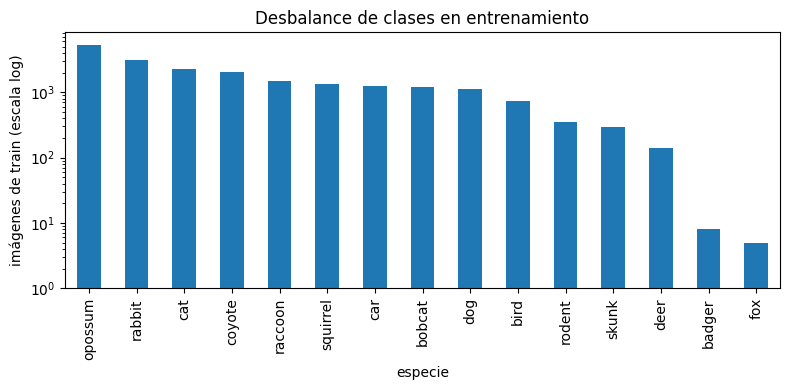

In [7]:
# 7. Estadísticas y desbalance
ann = ann.merge(data[["id", "split", "file", "W", "H"]], left_on="image_id", right_on="id", how="inner")
ann["especie"] = ann.category_id.map(cats)
tab1 = data.groupby("split").agg(imagenes=("id", "size"), con_animal=("has_animal", "sum"),
                                 ubicaciones=("location", "nunique"))
tab1["especies"] = ann.groupby("split").especie.nunique()
print(tab1)
tab1.to_csv(RES / "tabla1_dataset.csv")

cnt = ann[ann.split == "train"].groupby("especie").image_id.nunique().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 4)); cnt.plot.bar(ax=ax, log=True)
ax.set_ylabel("imágenes de train (escala log)"); ax.set_title("Desbalance de clases en entrenamiento")
plt.tight_layout(); plt.savefig(RES / "desbalance.png", dpi=150); plt.show()

## 6. Exportación a formato YOLO
Cada imagen se enlaza (symlink) y recibe su `.txt` con `clase cx cy w h` normalizados. Las imágenes vacías llevan archivo de etiquetas vacío (fondo). Las cajas COCO `[x, y, w, h]` se recortan a los límites de la imagen.

In [8]:
# 8. Exportar
import yaml
from PIL import Image
CLASSES = sorted(ann.especie.unique()); cls_id = {n: i for i, n in enumerate(CLASSES)}
json.dump(CLASSES, open(WORK / "classes.json", "w"), ensure_ascii=False)
print(len(CLASSES), "clases:", CLASSES)

# W/H faltantes -> leer del archivo
def fill_wh(df):
    for i in df.index[df.W.isna() | df.H.isna()]:
        with Image.open(df.at[i, "path"]) as im: df.at[i, "W"], df.at[i, "H"] = im.size
    return df
data = fill_wh(data)
wh = data.set_index("id")[["W", "H"]]
ann["W"], ann["H"] = ann.image_id.map(wh.W), ann.image_id.map(wh.H)

def yolo_line(c, b, W, H):
    x1, y1, x2, y2 = max(0, b[0]), max(0, b[1]), min(W, b[0] + b[2]), min(H, b[1] + b[3])
    if x2 - x1 < 2 or y2 - y1 < 2: return None
    return f"{c} {(x1+x2)/2/W:.6f} {(y1+y2)/2/H:.6f} {(x2-x1)/W:.6f} {(y2-y1)/H:.6f}"

lines = defaultdict(list)
for r in ann.itertuples():
    ln = yolo_line(cls_id[r.especie], r.bbox, r.W, r.H)
    if ln: lines[r.image_id].append((cls_id[r.especie], ln))

# Factor de sobremuestreo por imagen (solo train)
factor = {}
if OVERSAMPLE_MAX > 1:
    med = float(np.median(cnt.values))
    cf = {cls_id[e]: int(min(OVERSAMPLE_MAX, max(1, round(med / n)))) for e, n in cnt.items()}
    for iid, l in lines.items(): factor[iid] = max(cf[c] for c, _ in l)

def link_file(src, dst):
    # symlink -> hardlink -> copia (en Windows el symlink exige permisos; exFAT no admite hardlinks)
    for fn in (os.symlink, os.link):
        try: fn(src, dst); return
        except (OSError, NotImplementedError): pass
    shutil.copy2(src, dst)

SKIP_EXPORT = DATA.exists() and not REEXPORT and (DATA / "val_cis.yaml").exists()
if SKIP_EXPORT:
    print("yolo_data ya existe -> se omite la exportación (REEXPORT=False). Imágenes enlazadas/copiadas:", DATA)
else:
    if DATA.exists(): shutil.rmtree(DATA)
    for r in data.itertuples():
        src = Path(r.path).resolve()
        for k in range(factor.get(r.id, 1) if r.split == "train" else 1):
            stem = r.id if k == 0 else f"{r.id}_dup{k}"
            (DATA / "images" / r.split).mkdir(parents=True, exist_ok=True)
            (DATA / "labels" / r.split).mkdir(parents=True, exist_ok=True)
            dst = DATA / "images" / r.split / f"{stem}.jpg"
            link_file(src, dst)
            txt = "\n".join(l for _, l in lines.get(r.id, []))
            (DATA / "labels" / r.split / f"{stem}.txt").write_text(txt + ("\n" if txt else ""))

    for s in data.split.unique():
        yaml.safe_dump({"path": str(DATA.resolve()), "train": "images/train", "val": f"images/{s}",
                        "names": {i: n for i, n in enumerate(CLASSES)}},
                       open(DATA / f"{s}.yaml", "w"), allow_unicode=True)
    data.to_csv(WORK / "meta.csv", index=False)
    print("Exportado en", DATA)

15 clases: ['badger', 'bird', 'bobcat', 'car', 'cat', 'coyote', 'deer', 'dog', 'fox', 'opossum', 'rabbit', 'raccoon', 'rodent', 'skunk', 'squirrel']
yolo_data ya existe -> se omite la exportación (REEXPORT=False). Imágenes enlazadas/copiadas: work_q3\yolo_data


## 7. Entrenamiento (YOLOv8)
`strong` activa mosaic, mixup y copy-paste para debilitar la asociación fondo→especie. Para la ablación del informe, ejecuta esta celda con `AUG="base"`, luego `"strong"`, y luego `"strong"` con `OVERSAMPLE_MAX=3` (poniendo `REEXPORT = True`), cambiando `EXP_NAME` en cada caso.

In [11]:
# 9. Entrenar
from ultralytics import YOLO
AUG_PRESETS = {
  "base":   dict(mosaic=0.0, mixup=0.0, copy_paste=0.0, scale=0.3, hsv_h=0.015, hsv_s=0.4, hsv_v=0.3, fliplr=0.5),
  "strong": dict(mosaic=1.0, mixup=0.15, copy_paste=0.3, scale=0.6, hsv_h=0.03, hsv_s=0.7, hsv_v=0.5, fliplr=0.5, degrees=5.0),
}
# Pesos locales: evita la descarga automática desde GitHub (falla en redes con antivirus/proxy/VPN)
if not Path(WEIGHTS).exists():
    raise FileNotFoundError(f"Falta {Path(WEIGHTS).resolve()}. Descárgalo con el navegador desde "
        f"https://github.com/ultralytics/assets/releases/download/v8.4.0/{Path(WEIGHTS).name} y guárdalo en esa ruta.")
model = YOLO(str(Path(WEIGHTS).resolve()))
model.train(data=str(DATA / "val_cis.yaml"), imgsz=IMGSZ, epochs=EPOCHS, batch=BATCH, seed=SEED,
            deterministic=True, project=str(WORK / "runs"), name=EXP_NAME, exist_ok=True,
            patience=PATIENCE, cos_lr=True, device=DEVICE, fraction=TRAIN_FRACTION, **AUG_PRESETS[AUG])
BEST = WORK / "runs" / EXP_NAME / "weights" / "best.pt"
print(BEST)

New https://pypi.org/project/ultralytics/8.4.175 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.171  Python-3.13.14 torch-2.8.0 CPU (11th Gen Intel Core i7-1165G7 @ 2.80GHz)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.3, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=work_q3\yolo_data\val_cis.yaml, degrees=5.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=0.25, freeze=None, hsv_h=0.03, hsv_s=0.7, hsv_v=0.5, imgsz=416, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.15, mode=train, model=E:\Caltec

In [20]:
import os, shutil
from pathlib import Path

SRC = Path(r"E:\Caltech Camera Traps\Caltech Camera Traps\runs\detect\work_q3\runs\yolov8n_strong_cpu\weights\best.pt")
print("cwd:", os.getcwd())
print("existe:", SRC.exists(), "| es archivo:", SRC.is_file())
print("tamaño:", SRC.stat().st_size if SRC.exists() else None)

BEST_LOCAL = Path.home() / "cct_yolov8n_strong_cpu_best.pt"   # disco interno
shutil.copy2(SRC, BEST_LOCAL)
print("copiado a:", BEST_LOCAL, "|", BEST_LOCAL.stat().st_size, "bytes")

from ultralytics import YOLO
model = YOLO(str(BEST_LOCAL)); BEST = BEST_LOCAL
print("modelo cargado, clases:", len(model.names))

cwd: e:\Caltech Camera Traps\Caltech Camera Traps
existe: True | es archivo: True
tamaño: 6215786
copiado a: C:\Users\Erick D. Cajo\cct_yolov8n_strong_cpu_best.pt | 6215786 bytes
modelo cargado, clases: 15


In [23]:
import os
from pathlib import Path
os.chdir(r"E:\Caltech Camera Traps\Caltech Camera Traps")
ROOT = Path.cwd().resolve()
WORK = ROOT / "work_q3"
DATA = WORK / "yolo_data"
RES  = WORK / "results"
print(os.getcwd(), "|", (DATA / "val_cis.yaml").exists())

E:\Caltech Camera Traps\Caltech Camera Traps | True


## 8. Evaluación por partición y por especie (Tablas 2 y 3)

In [24]:
# 10. Evaluación
metrics, rows = {}, []
for s in ["val_cis", "val_trans", "test_cis", "test_trans"]:
    if not (DATA / f"{s}.yaml").exists(): continue
    m = model.val(data=str(DATA / f"{s}.yaml"), imgsz=IMGSZ, conf=0.001, iou=0.6, batch=BATCH, device=DEVICE,
                  project=str(WORK / "runs"), name=f"{EXP_NAME}_eval_{s}", exist_ok=True, plots=True, verbose=False)
    metrics[s] = {"mAP50": m.box.map50, "mAP50-95": m.box.map, "P": m.box.mp, "R": m.box.mr}
    for k, ci in enumerate(m.box.ap_class_index):
        rows.append({"split": s, "especie": CLASSES[int(ci)], "AP50": m.box.ap50[k], "AP50-95": m.box.ap[k]})
M = pd.DataFrame(metrics).T; print(M.round(4))
for k in ["val", "test"]:
    if f"{k}_cis" in M.index and f"{k}_trans" in M.index:
        print(f"brecha {k} (cis - trans):", (M.loc[f"{k}_cis", ["mAP50", "mAP50-95"]] - M.loc[f"{k}_trans", ["mAP50", "mAP50-95"]]).round(4).to_dict())
M.to_csv(RES / f"tabla2_metricas_{EXP_NAME}.csv")

PC = pd.DataFrame(rows)
PC["imgs_train"] = PC.especie.map(cnt).fillna(0).astype(int)
tab3 = PC[PC.split.isin(["test_cis", "test_trans"])].pivot(index="especie", columns="split", values="AP50")
tab3["imgs_train"] = cnt.reindex(tab3.index).fillna(0).astype(int)
tab3 = tab3.sort_values("imgs_train"); print(tab3.round(3))
tab3.to_csv(RES / f"tabla3_ap_por_especie_{EXP_NAME}.csv")
sub = PC[PC.split == "test_cis"]
print("Spearman (frecuencia vs AP50, test_cis):", round(sub.imgs_train.corr(sub.AP50, method="spearman"), 3))

Ultralytics 8.4.171  Python-3.13.14 torch-2.8.0 CPU (11th Gen Intel Core i7-1165G7 @ 2.80GHz)
Model summary (fused): 72 layers, 3,008,573 parameters, 0 gradients, 8.1 GFLOPs
WARNING val: Slow image access detected (ping: 27.411.2 ms, read: 9.22.9 MB/s, size: 432.2 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning E:\Caltech Camera Traps\Caltech Camera Traps\work_q3\yolo_data\labels\val_cis.cache... 2775 images, 220 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2775/2775 80.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 347/347 1.6it/s 3:420.6ss
                   all       2775       2639      0.646      0.486       0.51      0.341
Speed: 0.3ms preprocess, 16.2ms inference, 0.0ms loss, 0.4ms postprocess per image
Results saved to E:\Caltech Camera Traps\Caltech Camera Traps\work_q3\runs\yolov8n_strong_cpu_eval_val_

## 9. Robustez: tamaño y oclusión (Tabla 4)
CCT no anota oclusión, así que se usa un **indicador aproximado**: contraste de la caja contra un anillo de fondo y contacto con el borde. Es un proxy de camuflaje/oclusión parcial, no una medida directa; se declara así en el informe.

In [25]:
# 11. Robustez
import cv2
def iou(a, b):
    ix1, iy1, ix2, iy2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    u = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / u if u > 0 else 0.0

def read_gt(path, W, H):
    out = []
    if Path(path).exists():
        for ln in open(path):
            p = ln.split()
            if len(p) == 5:
                c, cx, cy, w, h = int(p[0]), *map(float, p[1:])
                out.append((c, [(cx-w/2)*W, (cy-h/2)*H, (cx+w/2)*W, (cy+h/2)*H]))
    return out

def occ_proxy(gray, box):
    H, W = gray.shape
    x1, y1, x2, y2 = [int(round(v)) for v in box]; x1, y1, x2, y2 = max(0, x1), max(0, y1), min(W, x2), min(H, y2)
    if x2-x1 < 3 or y2-y1 < 3: return 0.0, 1
    inside = gray[y1:y2, x1:x2].astype("float32")
    pw, ph = int(.25*(x2-x1))+2, int(.25*(y2-y1))+2
    X1, Y1, X2, Y2 = max(0, x1-pw), max(0, y1-ph), min(W, x2+pw), min(H, y2+ph)
    ring = gray[Y1:Y2, X1:X2].astype("float32"); mk = np.ones_like(ring, bool); mk[y1-Y1:y2-Y1, x1-X1:x2-X1] = False
    rp = ring[mk]
    if rp.size == 0: return 0.0, 1
    return abs(inside.mean() - rp.mean()) / (rp.std() + 1e-6), int(x1 <= 1 or y1 <= 1 or x2 >= W-1 or y2 >= H-1)

ROB_SPLIT, CONF = "test_trans", 0.25
files = [f for f in sorted((DATA / "images" / ROB_SPLIT).glob("*.jpg")) if "_dup" not in f.name]
recs = []
for i in range(0, len(files), 32):
    b = files[i:i+32]
    for f, pr in zip(b, model.predict([str(x) for x in b], imgsz=IMGSZ, conf=CONF, iou=0.6, device=DEVICE, verbose=False)):
        H, W = pr.orig_shape
        gts = read_gt(DATA / "labels" / ROB_SPLIT / f"{f.stem}.txt", W, H)
        if not gts: continue
        gray = cv2.cvtColor(cv2.imread(str(f)), cv2.COLOR_BGR2GRAY)
        dets = sorted([(int(c), float(s), bx.tolist()) for c, s, bx in zip(pr.boxes.cls, pr.boxes.conf, pr.boxes.xyxy)], key=lambda d: -d[1])
        used = set()
        for c, box in gts:
            best, bj = 0.0, -1
            for j, (dc, ds, db) in enumerate(dets):
                if j in used or dc != c: continue
                v = iou(box, db)
                if v > best: best, bj = v, j
            hit = best >= 0.5
            if hit: used.add(bj)
            ct, tb = occ_proxy(gray, box)
            recs.append(dict(img=f.name, especie=CLASSES[c], hit=int(hit), rel_area=(box[2]-box[0])*(box[3]-box[1])/(W*H),
                             contraste=ct, borde=tb))
R = pd.DataFrame(recs)
R["tamano"] = pd.cut(R.rel_area, [0, .01, .08, 1], labels=["pequeño", "mediano", "grande"])
q1, q2 = R.contraste.quantile([1/3, 2/3])
R["oclusion_proxy"] = np.where(R.borde == 1, "alto", np.where(R.contraste <= q1, "alto", np.where(R.contraste <= q2, "medio", "bajo")))
tab4 = pd.concat({c: R.groupby(c, observed=True).hit.agg(n="size", recall="mean") for c in ["oclusion_proxy", "tamano"]})
print(tab4.round(3)); tab4.to_csv(RES / f"tabla4_robustez_{EXP_NAME}.csv")

                           n  recall
oclusion_proxy alto     4309   0.661
               bajo     2509   0.542
               medio    3030   0.650
tamano         pequeño   709   0.188
               mediano  7032   0.650
               grande   2107   0.701


## 10. Grad-CAM sobre el backbone (Tabla 5)
Se deriva la puntuación de clase máxima de la salida respecto a la última capa del backbone (SPPF, capa 9). La **energía en caja** es la fracción del mapa normalizado dentro de las cajas reales; el **enriquecimiento** la divide por la fracción de área que ocupan esas cajas (≈1 = atención repartida como el área, sin preferencia por el animal).

In [26]:
# 12. Grad-CAM
import torch
net = model.model.to("cpu" if DEVICE == "cpu" else f"cuda:{DEVICE}").float().eval()
for p_ in net.parameters(): p_.requires_grad_(True)
LAYER = net.model[9]
dev = next(net.parameters()).device

def letterbox(img, size):
    h, w = img.shape[:2]; r = size / max(h, w); nh, nw = int(round(h*r)), int(round(w*r))
    can = np.full((size, size, 3), 114, np.uint8); t, l = (size-nh)//2, (size-nw)//2
    can[t:t+nh, l:l+nw] = cv2.resize(img, (nw, nh)); return can, (t, l, nh, nw)

def gradcam(img):
    can, (t, l, nh, nw) = letterbox(img, IMGSZ)
    x = torch.from_numpy(can[:, :, ::-1].copy()).permute(2, 0, 1).float().div(255)[None].to(dev).requires_grad_(True)
    st = {}; hk = LAYER.register_forward_hook(lambda m, i, o: st.__setitem__("a", o))
    out = net(x); hk.remove()
    pred = out[0] if isinstance(out, (tuple, list)) else out
    pred = pred[0] if pred.dim() == 3 else pred
    target = pred[4:, :].max(); act = st["a"]
    g = torch.autograd.grad(target, act)[0]
    cam = torch.relu((g.mean((2, 3), keepdim=True) * act).sum(1, keepdim=True))[0, 0].detach().cpu().numpy()
    cam = cv2.resize(cam, (IMGSZ, IMGSZ))[t:t+nh, l:l+nw]
    cam = cv2.resize(cam, (img.shape[1], img.shape[0])); return (cam - cam.min()) / (cam.max() - cam.min() + 1e-9)

N_CAM, N_VIS = 100, 6
(RES / "gradcam").mkdir(exist_ok=True); grows = []
for s in ["val_cis", "val_trans"]:
    fl = [f for f in sorted((DATA / "images" / s).glob("*.jpg")) if "_dup" not in f.name]; random.Random(SEED).shuffle(fl); n = 0
    for f in fl:
        img = cv2.imread(str(f)); H, W = img.shape[:2]
        gts = read_gt(DATA / "labels" / s / f"{f.stem}.txt", W, H)
        if not gts: continue
        cam = gradcam(img); m = np.zeros((H, W), bool)
        for _, b in gts: m[max(0, int(b[1])):int(b[3]), max(0, int(b[0])):int(b[2])] = True
        e, fr = cam[m].sum() / (cam.sum() + 1e-9), m.mean()
        grows.append(dict(split=s, energia_en_caja=e, fraccion_area=fr, enriquecimiento=e / max(fr, 1e-6)))
        if n < N_VIS:
            ov = cv2.addWeighted(img, .55, cv2.applyColorMap((cam*255).astype("uint8"), cv2.COLORMAP_JET), .45, 0)
            for _, b in gts: cv2.rectangle(ov, (int(b[0]), int(b[1])), (int(b[2]), int(b[3])), (255, 255, 255), 3)
            cv2.imwrite(str(RES / "gradcam" / f"{s}_{CLASSES[gts[0][0]]}_{f.stem}.jpg"), ov)
        n += 1
        if n >= N_CAM: break
tab5 = pd.DataFrame(grows).groupby("split").mean(); print(tab5.round(3)); tab5.to_csv(RES / f"tabla5_gradcam_{EXP_NAME}.csv")

           energia_en_caja  fraccion_area  enriquecimiento
split                                                     
val_cis              0.083          0.066            1.532
val_trans            0.066          0.071            1.519


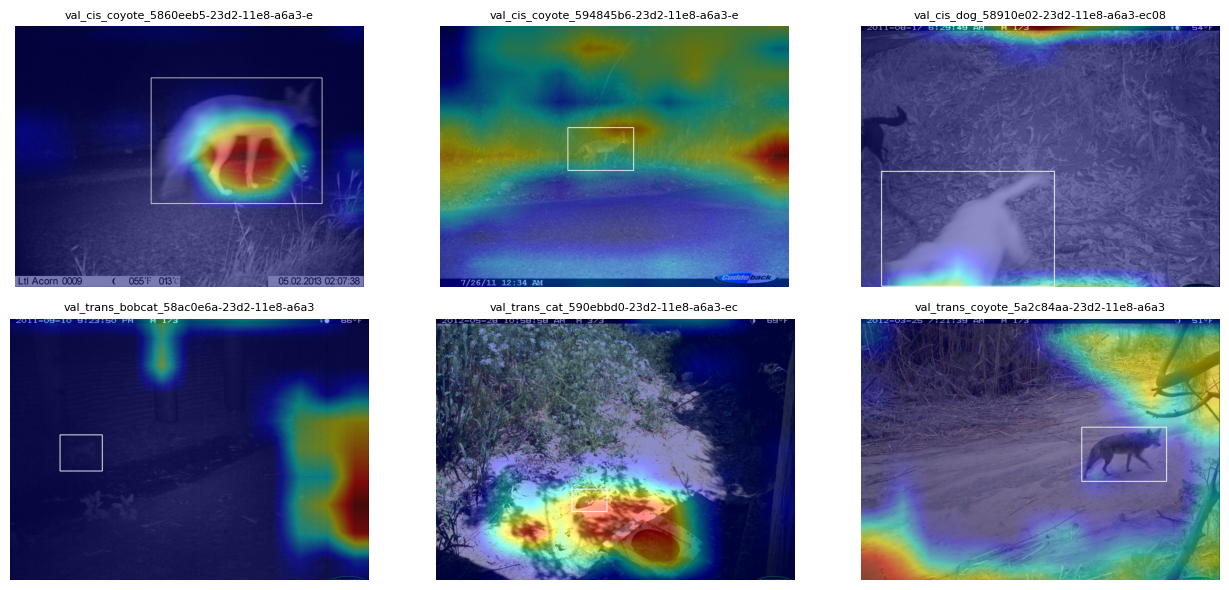

In [27]:
# Galería de Grad-CAM (cis arriba, trans abajo)
imgs = sorted((RES / "gradcam").glob("*.jpg"))
sel = [f for f in imgs if f.name.startswith("val_cis")][:3] + [f for f in imgs if f.name.startswith("val_trans")][:3]
if sel:
    fig, axs = plt.subplots(2, 3, figsize=(13, 6))
    for ax, f in zip(axs.ravel(), sel):
        ax.imshow(cv2.cvtColor(cv2.imread(str(f)), cv2.COLOR_BGR2RGB)); ax.set_title(f.stem[:40], fontsize=8); ax.axis("off")
    plt.tight_layout(); plt.savefig(RES / "gradcam_galeria.png", dpi=150); plt.show()

## 11. Módulo de monitoreo ecológico (Tabla 6)
Sobre una cámara **no vista** (`test_trans`): se detecta con umbral de confianza, se agrupa por especie y periodo y se cuenta un *evento* cuando una secuencia tiene la especie en ≥ `MIN_FRAMES` fotogramas.

Cámara: 100 | imágenes: 4320
{'imagenes': 4320, 'con_fauna': 3860, 'vacias': 460, 'tasa_vacias': 0.106}
          detecciones  fotogramas  conf_media             primera  \
especie                                                             
raccoon          3078        2582       0.777 2010-05-25 20:32:56   
opossum           830         817       0.648 2010-05-25 22:35:28   
dog               494         380       0.772 2010-05-25 13:39:25   
cat               206         206       0.580 2010-05-28 02:54:21   
coyote            124         123       0.543 2010-05-25 20:32:56   
squirrel           96          93       0.530 2010-05-30 11:37:56   
bird               77          74       0.415 2010-05-26 11:48:20   
rabbit             59          59       0.498 2010-06-05 03:01:39   
bobcat             18          18       0.386 2010-06-03 21:10:44   
deer                2           2       0.391 2010-08-13 10:08:39   
skunk               1           1       0.270 2010-07-17 13:41:55   

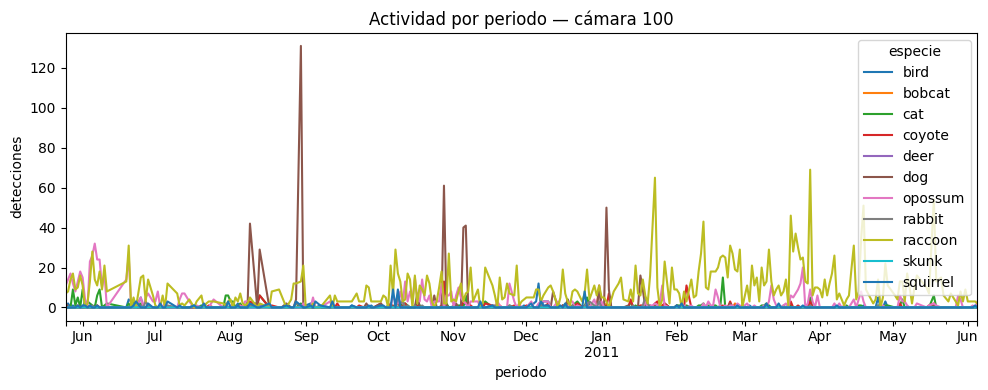

In [30]:
# 13. Monitoreo
MON_SPLIT, MON_CONF, MIN_FRAMES, PERIODO = "test_trans", 0.25, 2, "D"   # "H" hora, "D" día, "M" mes
meta = pd.read_csv(WORK / "meta.csv", parse_dates=["dt"])
meta = meta[meta.split == MON_SPLIT]
LOC = meta.location.astype(str).value_counts().index[0]            # cámara más poblada (cámbiala si quieres otra)
cam_df = meta[meta.location.astype(str) == LOC].sort_values(["dt", "frame"])
print("Cámara:", LOC, "| imágenes:", len(cam_df))

recs = []
fl = [str(DATA / "images" / MON_SPLIT / f"{i}.jpg") for i in cam_df.id]
for i in range(0, len(fl), 32):
    for j, pr in enumerate(model.predict(fl[i:i+32], imgsz=IMGSZ, conf=MON_CONF, iou=0.6, device=DEVICE, verbose=False)):
        r = cam_df.iloc[i + j]
        for c, s_ in zip(pr.boxes.cls, pr.boxes.conf):
            recs.append(dict(id=r["id"], dt=r["dt"], seq_id=r["seq_id"], especie=CLASSES[int(c)], conf=float(s_)))
L = pd.DataFrame(recs)
n_img, n_fauna = len(cam_df), L.id.nunique() if len(L) else 0
print(dict(imagenes=n_img, con_fauna=n_fauna, vacias=n_img - n_fauna, tasa_vacias=round((n_img - n_fauna) / max(n_img, 1), 3)))
if len(L):
    ev = L.groupby(["seq_id", "especie"]).id.nunique().reset_index(name="frames")
    ev = ev[ev.frames >= MIN_FRAMES].groupby("especie").size().rename("eventos")
    tab6 = L.groupby("especie").agg(detecciones=("conf", "size"), fotogramas=("id", "nunique"), conf_media=("conf", "mean"),
                                    primera=("dt", "min"), ultima=("dt", "max")).join(ev).fillna({"eventos": 0})
    tab6["eventos"] = tab6.eventos.astype(int); print(tab6.sort_values("detecciones", ascending=False).round(3))
    tab6.to_csv(RES / "tabla6_monitoreo_por_especie.csv")
    L["periodo"] = L["dt"].dt.to_period(PERIODO)
    act = L.pivot_table(index="periodo", columns="especie", values="id", aggfunc="count", fill_value=0)
    act.to_csv(RES / "monitoreo_por_periodo.csv"); act.plot(figsize=(10, 4), title=f"Actividad por periodo — cámara {LOC}")
    plt.ylabel("detecciones"); plt.tight_layout(); plt.savefig(RES / "monitoreo_actividad.png", dpi=150); plt.show()

## 12. Qué llevar al informe
- **Tabla 1** → `results/tabla1_dataset.csv`; **Tabla 2/3** → `tabla2_*`, `tabla3_*`; **Tabla 4** → `tabla4_*`; **Tabla 5** → `tabla5_*`; **Tabla 6** → `tabla6_*`.
- Figuras: `desbalance.png`, `gradcam_galeria.png`, `monitoreo_actividad.png`, y las curvas PR / matriz de confusión en `runs/*_eval_*`.
- Repite las celdas 9–12 para las configuraciones A (`base`), B (`strong`) y C (`strong` + `OVERSAMPLE_MAX=3`, poniendo `REEXPORT = True`) y compara las Tablas 2 y 3.
- La brecha *cis − trans* y el enriquecimiento de Grad-CAM deben leerse juntos: ninguno de los dos prueba por sí solo que el modelo use el fondo.